# CAT eval: where do `old` and `new` differ?

Setup mimics raw processing:

* `w0` = the scene white in linear Rec.2020, as derived from the camera WB multipliers (green-normalised, like `wbColorspaceConvert` in `module.zig`).
* `p` = camera colours, already in Rec.2020 (`decodeColour`), **not** white balanced. Here they are ColorChecker reflectances lit by a CIE D illuminant at `T` kelvin, so the camera is "perfect" and any error comes from the adaptation only.
* **Ground truth** = the same reflectances lit by D65. A correct WB/CAT should map `p` onto this.

Methods (all take `p, w0`):

| name | what | where |
|---|---|---|
| `none` | no adaptation (baseline) | |
| `gain` | `p / w0`, plain per-channel gain in Rec.2020 | |
| `new` | `cat16(p, w0, D65)` | active code in `node.color.zig` |
| `old` | `cat16(p, D65, 1/w0)` | the commented "vkdt style" block |
| `colour` | `colour`'s CAT16 von Kries on XYZ (sanity check of my `cat16`) | |

In [157]:
import warnings
import colour
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

warnings.filterwarnings("ignore", category=colour.utilities.ColourUsageWarning)
np.set_printoptions(precision=5, suppress=True, linewidth=140)

# ---- matrices (same values as src/math/matrices.zig and node.color.zig) ----
CAT16_M = np.array(
    [
        [0.401288, 0.650173, -0.051461],
        [-0.250268, 1.204414, 0.045854],
        [-0.002079, 0.048952, 0.953127],
    ]
)
CAT16_M_INV = np.array(
    [
        [1.86206786, -1.01125463, 0.14918677],
        [0.38752654, 0.62144744, -0.00897398],
        [-0.01584150, -0.03412294, 1.04996444],
    ]
)
XYZ_FROM_REC2020 = np.array(
    [
        [0.636958048301291, 0.1446169035862084, 0.16888097516417205],
        [0.2627002120112669, 0.6779980715188711, 0.05930171646986194],
        [0.0, 0.02807269304908745, 1.0609850577107907],
    ]
)
REC2020_FROM_XYZ = np.array(
    [
        [1.71665119, -0.35567078, -0.25336628],
        [-0.66668435, 1.61648124, 0.01576855],
        [0.01763986, -0.04277061, 0.94210312],
    ]
)
print("|M @ M_inv - I| max      :", np.abs(CAT16_M @ CAT16_M_INV - np.eye(3)).max())
print(
    "|rec2020 fwd @ inv - I|  :",
    np.abs(XYZ_FROM_REC2020 @ REC2020_FROM_XYZ - np.eye(3)).max(),
)

CONE_FROM_REC2020 = CAT16_M @ XYZ_FROM_REC2020
REC2020_FROM_CONE = REC2020_FROM_XYZ @ CAT16_M_INV
D65 = np.ones(3)
XYZ_D65 = XYZ_FROM_REC2020 @ D65

|M @ M_inv - I| max      : 7.72968000966e-09
|rec2020 fwd @ inv - I|  : 3.55095253661e-09


In [158]:
# ---- CCT <-> Rec.2020 (CIE D locus) ----
CCT_MIN, CCT_MAX = 4000.0, 25000.0


def _xy_to_uv(xy):
    x, y = xy
    d = -2.0 * x + 12.0 * y + 3.0
    return np.array([4.0 * x / d, 9.0 * y / d])


def cct_rec2020(cct):
    xy = np.asarray(colour.temperature.CCT_to_xy_CIE_D(cct), dtype=np.float64)
    return xy, REC2020_FROM_XYZ @ np.asarray(colour.xy_to_XYZ(xy), dtype=np.float64)


def rec2020_cct(rgb):
    """Linear Rec.2020 -> (CCT on the CIE D locus [K], unsigned Duv in CIE1960 uv)."""
    XYZ = XYZ_FROM_REC2020 @ np.asarray(rgb, dtype=np.float64)
    uv = _xy_to_uv(colour.XYZ_to_xy(XYZ))

    def err(t):
        return np.sum(
            (_xy_to_uv(np.asarray(colour.temperature.CCT_to_xy_CIE_D(t))) - uv) ** 2
        )

    r = minimize_scalar(
        err, bounds=(CCT_MIN, CCT_MAX), method="bounded", options={"xatol": 1e-3}
    )
    return float(r.x), float(np.sqrt(r.fun))

In [159]:
# ---- methods ----
def cat16(rgb, src, dst):
    cone = CONE_FROM_REC2020 @ rgb
    cone = cone * (CONE_FROM_REC2020 @ dst) / (CONE_FROM_REC2020 @ src)
    return REC2020_FROM_CONE @ cone


def m_none(p, w0):
    return np.array(p)


def m_gain(p, w0):
    return p / w0


def m_new(p, w0):
    return cat16(p, w0, D65)


def m_old(p, w0):
    return cat16(p, D65, 1.0 / w0)


def m_colour(p, w0):
    to_xyz = lambda v: XYZ_FROM_REC2020 @ v
    XYZ_a = colour.adaptation.chromatic_adaptation_VonKries(
        to_xyz(p), to_xyz(w0), to_xyz(D65), transform="CAT16"
    )
    return REC2020_FROM_XYZ @ XYZ_a


METHODS = {
    "none": m_none,
    "gain": m_gain,
    "new": m_new,
    "old": m_old,
    "colour": m_colour,
}

## 0. Sanity: is my `cat16` the same as `colour`'s CAT16 von Kries?
If not, nothing below can be trusted.

In [160]:
_, w = cct_rec2020(7500)
rng = np.random.default_rng(0)
p = rng.uniform(0.05, 1.0, (100, 3))
d = np.abs(
    np.array([m_new(x, w) for x in p]) - np.array([m_colour(x, w) for x in p])
).max()
print("max |new - colour CAT16| =", d)

max |new - colour CAT16| = 9.31518195912e-09


## 1. Algebra: when are `old` and `new` the same?

With `C = CONE_FROM_REC2020` and `c(v) = C @ v`:

* `new = C^-1 . diag(c(D65) / c(w0)) . C . p`
* `old = C^-1 . diag(c(1/w0) / c(D65)) . C . p`

They are identical iff `c(1/w0) * c(w0) = c(D65)^2` per cone channel. The per-channel reciprocal (`1/w0`) is taken in **Rec.2020**, but the division happens in **cone space**; since `C` isn't diagonal, `c(1/w0) != 1/c(w0)`. So `old` is only a first-order approximation of a white balance, and it does **not** map `w0` to D65.

In [161]:
print(
    f"{'CCT':>6} | {'c(1/w0)*c(w0)/c(D65)^2 (1 = old==new)':^42} | {'old(w0)':^26} | {'new(w0)':^26}"
)
for T in (4000, 5000, 6504, 7500, 10000, 15000, 25000):
    _, w = cct_rec2020(T)
    ratio = (
        (CONE_FROM_REC2020 @ (1 / w))
        * (CONE_FROM_REC2020 @ w)
        / (CONE_FROM_REC2020 @ D65) ** 2
    )
    print(
        f"{T:>6} | {np.array2string(ratio, precision=4):^42} | {np.array2string(m_old(w, w), precision=4):^26} | {np.array2string(m_new(w, w), precision=4):^26}"
    )

   CCT |   c(1/w0)*c(w0)/c(D65)^2 (1 = old==new)    |          old(w0)           |          new(w0)          
  4000 |         [ 1.0346  1.0325  1.023 ]          | [ 1.039   1.0322  1.0223]  |       [ 1.  1.  1.]       
  5000 |         [ 1.0075  1.0073  1.0053]          | [ 1.008   1.0073  1.0051]  |       [ 1.  1.  1.]       
  6504 |               [ 1.  1.  1.]                |       [ 1.  1.  1.]        |       [ 1.  1.  1.]       
  7500 |         [ 1.0013  1.0013  1.001 ]          | [ 1.0013  1.0013  1.0009]  |       [ 1.  1.  1.]       
 10000 |         [ 1.0083  1.0085  1.0064]          | [ 1.008   1.0088  1.0062]  |       [ 1.  1.  1.]       
 15000 |         [ 1.02    1.0207  1.0158]          | [ 1.0186  1.0216  1.0154]  |       [ 1.  1.  1.]       
 25000 |         [ 1.0312  1.0326  1.0251]          | [ 1.0283  1.0343  1.0246]  |       [ 1.  1.  1.]       


## 2. The white patch itself
A patch equal to `w0` must come out as D65 (`1,1,1`, i.e. ~6507.65 K / Duv 6e-5 by `rec2020_cct`; **not** 6500 K - D65 is not exactly on the D-series locus). Anything else is a neutrality error.

In [162]:
print(f"{'T':>6} | " + " | ".join(f"{n:^38}" for n in ("gain", "new", "old")))
for T in (4000, 5000, 6504, 7500, 10000, 15000, 25000):
    _, w = cct_rec2020(T)
    cells_ = []
    for n in ("gain", "new", "old"):
        o = METHODS[n](w, w)
        c, duv = rec2020_cct(o)
        cells_.append(f"{c:7.1f}K duv={duv:.5f} maxdev={np.abs(o - 1).max():.4f}")
    print(f"{T:>6} | " + " | ".join(f"{s:^38}" for s in cells_))

     T |                  gain                  |                  new                   |                  old                  
  4000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6426.3K duv=0.00030 maxdev=0.0390  
  5000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6492.0K duv=0.00005 maxdev=0.0080  
  6504 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000  
  7500 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6505.4K duv=0.00005 maxdev=0.0013  
 10000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6495.5K duv=0.00006 maxdev=0.0088  
 15000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |    6483.2K duv=0.00031 maxdev=0.0216  
 25000 |    6507.7K duv=0.00006 maxdev=0.0000   |    6507.7K duv=0.00006 maxdev=0.0000   |

## 3. Ground truth: ColorChecker under illuminant `T` -> D65
"Perfect camera" = Rec.2020 of XYZ under the illuminant, white normalised to G=1 like the WB multipliers. Reference = same reflectances under D65. Error is CIEDE2000 with the D65 white.

In [163]:
CMFS = colour.MSDS_CMFS["CIE 1931 2 Degree Standard Observer"]
CC = colour.SDS_COLOURCHECKERS["ColorChecker N Ohta"]
CC_NAMES = list(CC.keys())
CC_SDS = [CC[n] for n in CC_NAMES]
ILL_D65 = colour.SDS_ILLUMINANTS["D65"]
ONES = colour.SpectralDistribution(dict.fromkeys(ILL_D65.wavelengths, 1.0))
SHAPE = ILL_D65.shape


def illum_D(T):
    return colour.sd_CIE_illuminant_D_series(colour.temperature.CCT_to_xy_CIE_D(T))


def xyz_under(sd, ill):
    return colour.sd_to_XYZ(sd, CMFS, ill) / 100.0


def scene(T):
    """-> (p [24x3 camera-like Rec.2020, white G=1], w0 [3], truth [24x3 Rec.2020 under D65])"""
    ill = illum_D(T)
    w = REC2020_FROM_XYZ @ xyz_under(ONES, ill)
    g = w[1]  # green normalisation of the WB (wbColorspaceConvert)
    p = np.array([REC2020_FROM_XYZ @ xyz_under(sd, ill) for sd in CC_SDS]) / g
    truth = np.array([REC2020_FROM_XYZ @ xyz_under(sd, ILL_D65) for sd in CC_SDS])
    return p, w / g, truth


def to_lab(rgb):
    XYZ = np.maximum(rgb @ XYZ_FROM_REC2020.T, 1e-6)
    return colour.XYZ_to_Lab(XYZ, colour.XYZ_to_xy(XYZ_D65))


def de2000(a, b):
    return colour.delta_E(to_lab(a), to_lab(b), method="CIE 2000")


def run(T):
    p, w0, truth = scene(T)
    return {n: np.array([f(x, w0) for x in p]) for n, f in METHODS.items()}, truth, w0


# sanity: the "white 9.5" patch under D65 is ~neutral
_, _, tr = scene(6504)
print("reflectance-white under D65 (patch 19, 'white 9.5'):", tr[18])

reflectance-white under D65 (patch 19, 'white 9.5'): [ 0.88699  0.88831  0.876  ]


mean / max dE2000 vs ground truth (24 ColorChecker patches)
     T |     none      |     gain      |      new      |      old      |    colour    
  4000 | 11.71 /19.64 |  1.03 / 2.84 |  1.73 / 3.65 |  2.00 / 4.33 |  1.73 / 3.65
  4500 |  8.69 /16.06 |  0.75 / 2.05 |  1.23 / 2.57 |  1.34 / 2.90 |  1.23 / 2.57
  5000 |  6.10 /12.26 |  0.52 / 1.39 |  0.82 / 1.71 |  0.86 / 1.85 |  0.82 / 1.71
  5500 |  3.82 / 8.32 |  0.32 / 0.85 |  0.49 / 1.02 |  0.50 / 1.07 |  0.49 / 1.02
  6000 |  1.81 / 4.24 |  0.15 / 0.39 |  0.22 / 0.46 |  0.23 / 0.47 |  0.22 / 0.46
  7000 |  1.53 / 3.87 |  0.13 / 0.33 |  0.18 / 0.38 |  0.18 / 0.38 |  0.18 / 0.38
  7500 |  2.81 / 6.81 |  0.25 / 0.62 |  0.34 / 0.71 |  0.35 / 0.71 |  0.34 / 0.71
  8500 |  4.76 /10.82 |  0.46 / 1.09 |  0.60 / 1.22 |  0.61 / 1.30 |  0.60 / 1.22
 10000 |  6.79 /14.45 |  0.69 / 1.68 |  0.87 / 1.81 |  0.90 / 1.99 |  0.87 / 1.81
 12500 |  8.88 /17.71 |  0.97 / 2.41 |  1.17 / 2.48 |  1.23 / 2.80 |  1.17 / 2.48
 15000 | 10.15 /19.50 |  1.16 / 2

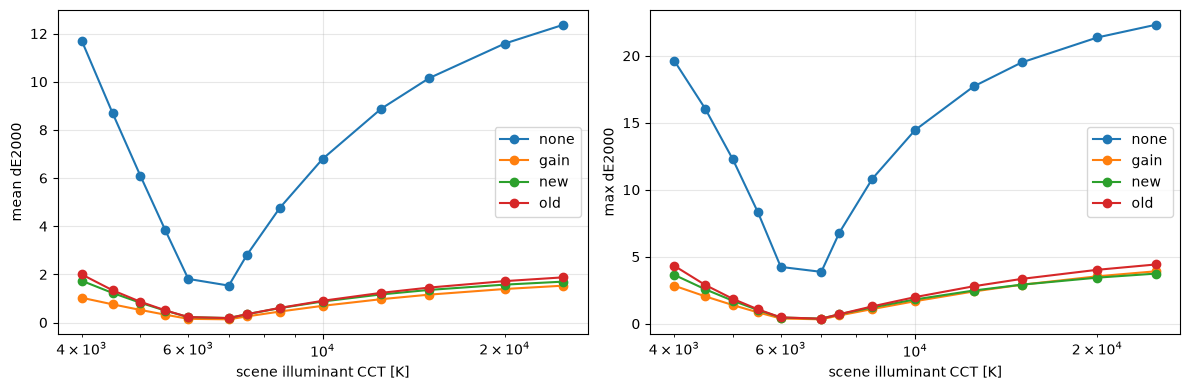

In [164]:
TS = [4000, 4500, 5000, 5500, 6000, 7000, 7500, 8500, 10000, 12500, 15000, 20000, 25000]
stats = {n: [] for n in METHODS}
for T in TS:
    out, truth, w0 = run(T)
    for n in METHODS:
        stats[n].append(de2000(out[n], truth))
stats = {n: np.array(v) for n, v in stats.items()}  # [len(TS), 24]

print("mean / max dE2000 vs ground truth (24 ColorChecker patches)")
print(f"{'T':>6} | " + " | ".join(f"{n:^13}" for n in METHODS))
for i, T in enumerate(TS):
    print(
        f"{T:>6} | "
        + " | ".join(
            f"{stats[n][i].mean():5.2f} /{stats[n][i].max():5.2f}" for n in METHODS
        )
    )

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in METHODS:
    if n == "colour":
        continue
    ax[0].plot(TS, [s.mean() for s in stats[n]], "o-", label=n)
    ax[1].plot(TS, [s.max() for s in stats[n]], "o-", label=n)
for a, t in zip(ax, ("mean dE2000", "max dE2000")):
    a.set_xlabel("scene illuminant CCT [K]")
    a.set_ylabel(t)
    a.set_xscale("log")
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

## 4. Per-patch errors at one illuminant
Which patches are the problem children (saturated blues/oranges usually)? Change `T`.

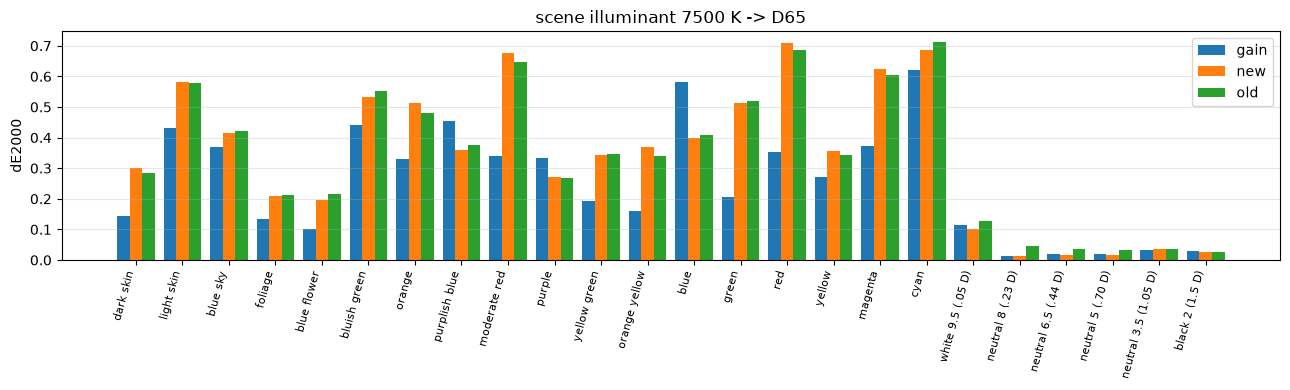

In [165]:
T = 7500
out, truth, w0 = run(T)
errs = {n: de2000(out[n], truth) for n in ("gain", "new", "old")}
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(24)
bw = 0.27
for k, n in enumerate(errs):
    ax.bar(x + (k - 1) * bw, errs[n], bw, label=n)
ax.set_xticks(x)
ax.set_xticklabels(CC_NAMES, rotation=75, ha="right", fontsize=8)
ax.set_ylabel("dE2000")
ax.set_title(f"scene illuminant {T} K -> D65")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 5. Visual: one panel per method, ColorChecker layout (4x6)
First panel is the ground truth. Encoded to sRGB for display only; out-of-gamut values are clipped.

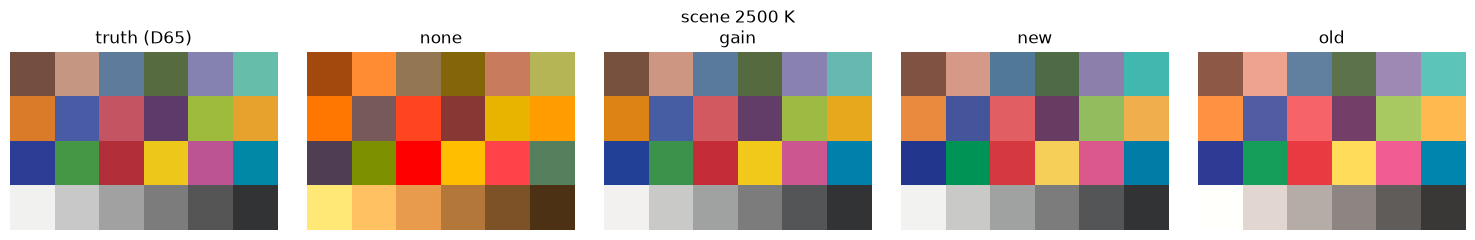

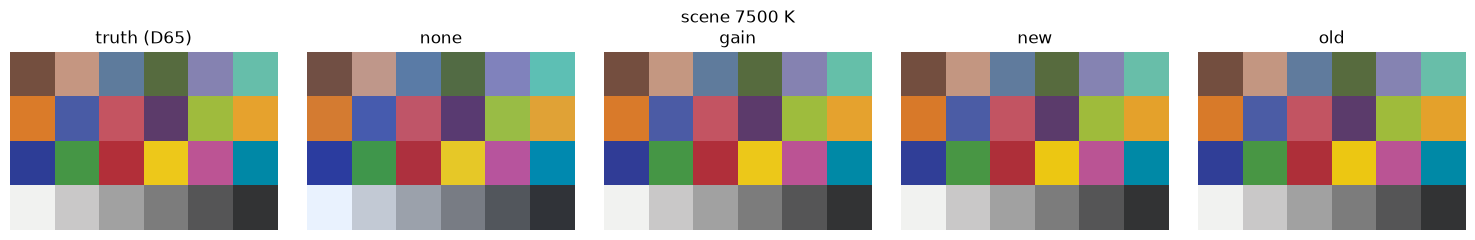

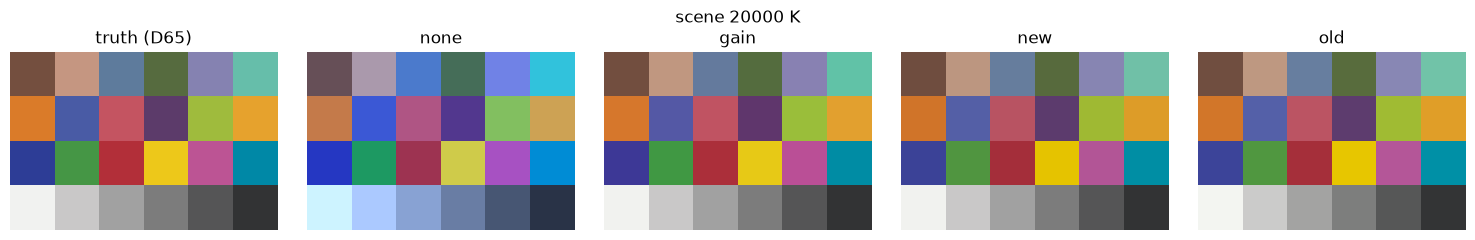

In [166]:
def srgb(rgb):
    XYZ = rgb @ XYZ_FROM_REC2020.T
    return np.clip(colour.XYZ_to_sRGB(XYZ), 0, 1)


def show(T, names=("none", "gain", "new", "old")):
    out, truth, w0 = run(T)
    rows = [("truth (D65)", truth)] + [(n, out[n]) for n in names]
    fig, ax = plt.subplots(1, len(rows), figsize=(3 * len(rows), 2.4))
    for a, (n, r) in zip(ax, rows):
        a.imshow(srgb(r).reshape(4, 6, 3), interpolation="nearest")
        a.set_title(n)
        a.axis("off")
    fig.suptitle(f"scene {T} K")
    plt.tight_layout()
    plt.show()


for T in (2500, 7500, 20000):
    show(T)

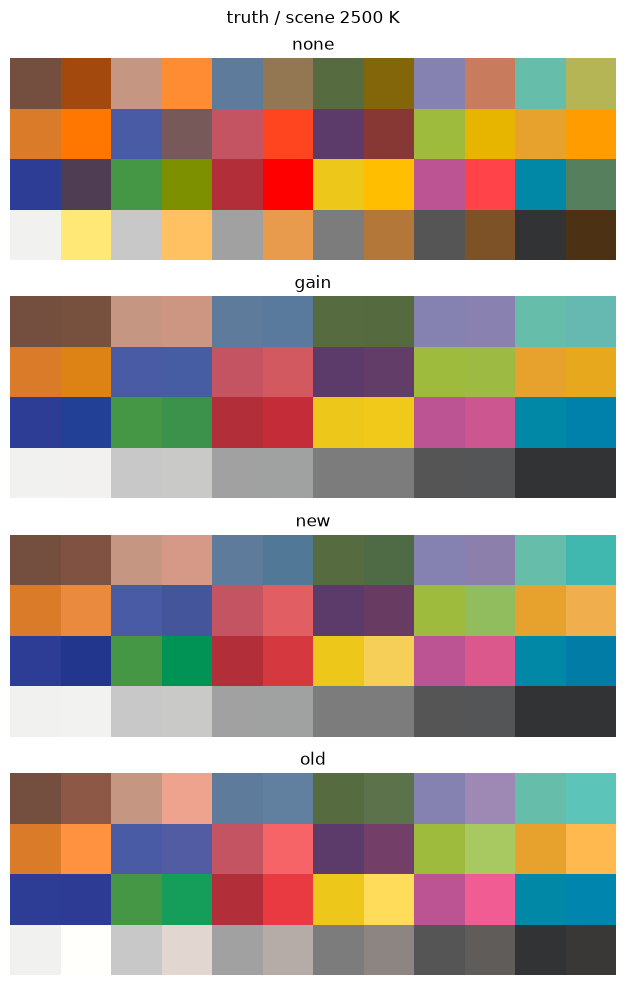

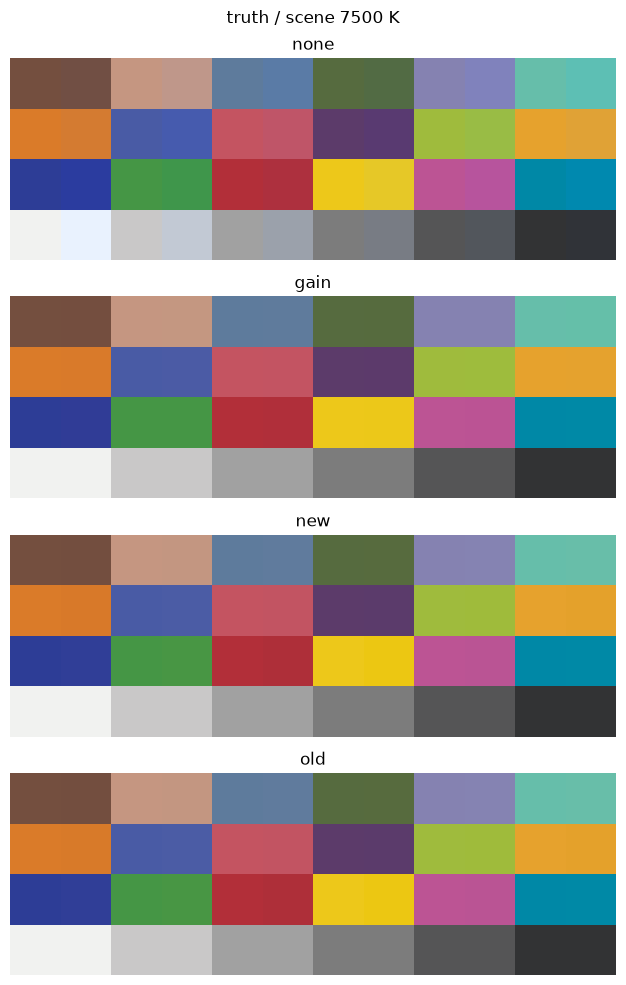

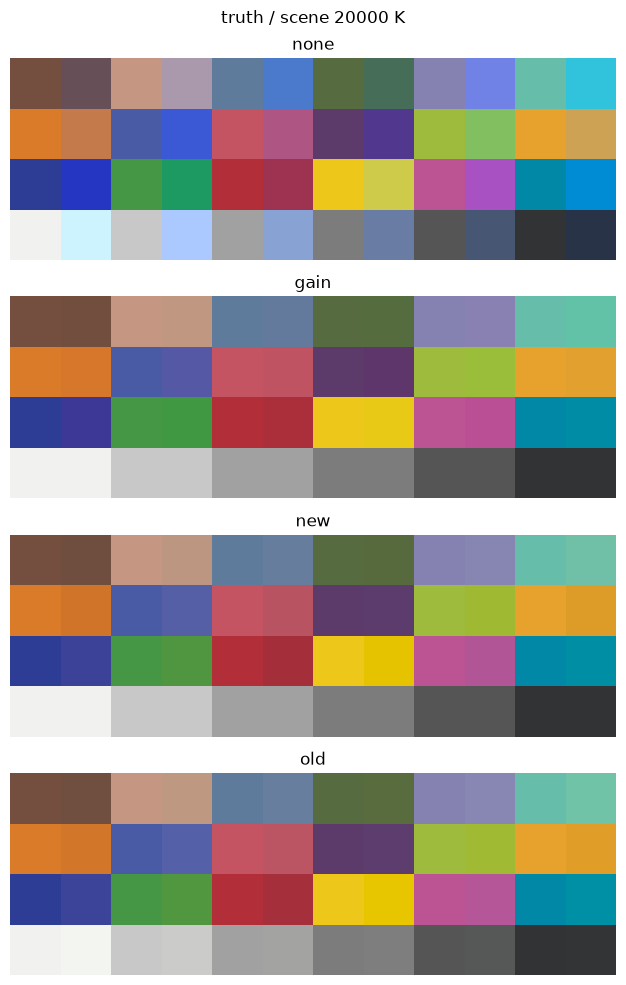

In [195]:
def show(T, names=("none", "gain", "new", "old")):
    out, truth, w0 = run(T)
    rows = [(n, out[n]) for n in names]
    fig, ax = plt.subplots(len(rows), 1, figsize=(10, 10))
    for a, (n, r) in zip(ax, rows):
        a.imshow(
            np.column_stack((srgb(truth), srgb(r))).reshape(4, 6 * 2, 3),
            interpolation="nearest",
        )
        a.set_title(n)
        a.axis("off")
    fig.suptitle(f"truth / scene {T} K")
    plt.tight_layout()
    plt.show()


for T in (2500, 7500, 20000):
    show(T)

## 6. Chromaticity of the neutral ramp after adaptation
Patches 19-24 of the ColorChecker are the grey ramp; all should land on D65.

In [168]:
T = 7500
out, truth, w0 = run(T)
grey = slice(18, 24)
print(f"grey ramp, scene {T} K, CCT/Duv of the output (target ~6507.65 K, duv 6e-5)")
for n in ("none", "gain", "new", "old"):
    cs = [rec2020_cct(r) for r in out[n][grey]]
    print(f"{n:>5}: " + "  ".join(f"{c:7.1f}K/{d:.4f}" for c, d in cs))
print(
    "truth: "
    + "  ".join(f"{c:7.1f}K/{d:.4f}" for c, d in [rec2020_cct(r) for r in truth[grey]])
)

grey ramp, scene 7500 K, CCT/Duv of the output (target ~6507.65 K, duv 6e-5)
 none:  7393.7K/0.0004   7475.6K/0.0002   7517.7K/0.0001   7524.2K/0.0002   7675.8K/0.0003   7970.6K/0.0001
 gain:  6428.3K/0.0005   6483.1K/0.0002   6514.4K/0.0002   6518.8K/0.0002   6632.6K/0.0003   6841.1K/0.0001
  new:  6428.0K/0.0005   6483.4K/0.0002   6514.5K/0.0002   6518.9K/0.0002   6631.8K/0.0003   6839.8K/0.0001
  old:  6425.9K/0.0005   6481.2K/0.0002   6512.3K/0.0001   6516.7K/0.0002   6629.5K/0.0003   6837.4K/0.0001
truth:  6432.1K/0.0004   6484.5K/0.0002   6515.3K/0.0001   6519.3K/0.0002   6633.1K/0.0003   6839.7K/0.0001


## 7. A real camera white: the DSC_6765.NEF values from `module.zig`'s test
Port of `wbColorspaceConvert`: camera WB multipliers -> Rec.2020 gain. Note this passes the as-shot white through `xyz_d65_from_cam`, which is a *D65* matrix, so the white is only as correct as that matrix is at the shot illuminant. Duv tells you if the white is on the daylight locus; if it isn't (tint), the D-series ground truth above doesn't apply.

In [169]:
cam_mul = np.array([1.90625, 1.0, 1.4921875])
xyz_d65_from_cam = np.array(
    [
        [1.5699793, 0.14481506, 0.10475578],
        [0.6360732, 0.8477491, -0.221411],
        [0.12701747, -0.2259345, 1.4544346],
    ]
)


def wb_colorspace_convert(xyz_d65_from_cam, wb_coeffs_cam):
    white_cam = 1.0 / wb_coeffs_cam
    white = REC2020_FROM_XYZ @ (xyz_d65_from_cam @ white_cam)
    white = white / white[1]
    return 1.0 / white


gain = wb_colorspace_convert(xyz_d65_from_cam, cam_mul)
w0 = 1.0 / gain
print("gain (zig test expects 0.8191874, 1, 1.3340929):", gain)
print("w0 = scene white in Rec.2020:", w0)
cct, duv = rec2020_cct(w0)
print(f"scene white: {cct:.0f} K, duv={duv:.4f}")
print(
    "new(w0) =",
    m_new(w0, w0),
    "   old(w0) =",
    m_old(w0, w0),
    "   gain(w0) =",
    m_gain(w0, w0),
)

gain (zig test expects 0.8191874, 1, 1.3340929): [ 0.81919  1.       1.33409]
w0 = scene white in Rec.2020: [ 1.22072  1.       0.74957]
scene white: 4629 K, duv=0.0068
new(w0) = [ 1.  1.  1.]    old(w0) = [ 1.02526  1.0106   1.00629]    gain(w0) = [ 1.  1.  1.]


## Notes / things to try
* `old` is a gain in disguise: it multiplies cone responses by `c(1/w0)`; `new` divides by `c(w0)`. They agree to first order and diverge as `w0` leaves D65 (see section 1 ratios) and on saturated colours.
* To test tint, replace `illum_D(T)` with a non-daylight SD (e.g. `colour.SDS_ILLUMINANTS["FL2"]`, `"A"`) and build `w0` from it; `rec2020_cct`'s Duv will be large.
* `xyz_d65_from_cam` only exists for D65. For a real camera, interpolate DNG ColorMatrix1/2 by the scene CCT before computing `w0` (that is the standard DNG recipe).